<a href="https://colab.research.google.com/github/Emzogwayo/SemProject_MLEngine/blob/main/K-Means_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Madaraka Connect — Spatial Deduplication Model

**ICS 3202: Artificial Intelligence — Project Deliverable 2**

**Project:** A Web-Based Reporting and Dispatch System for Water, Electricity and Waste Services in Madaraka Estate

**Group Members:**
- 189592 - Tiffany Maina
- 167925 - Eniola Fabunmi
- 189923 - Emma Ogwayo

**Institution:** School of Computing and Engineering Sciences (SCES), Strathmore University  

---

## The Problem

Madaraka Estate is a high-density residential community in Nairobi whose water, electricity and waste infrastructure is under constant strain. When a fault occurs — a burst main pipe, a blown transformer, an overflowing bin — residents currently report it through fragmented channels: WhatsApp groups, phone calls, USSD shortcodes, or physical visits to sub-county offices.

The critical failure of these channels is **duplicate reporting**. When a single visible fault (e.g. a burst pipe on a main road) affects dozens of households, each resident independently reports it. The dispatcher receives 30–40 near-identical tickets for one physical incident, cannot distinguish them from 30–40 genuinely separate faults, and loses time manually cross-referencing locations before dispatching a crew. This is exactly the problem that commercial civic platforms (SeeClickFix, FixMyStreet) solve with spatial cross-referencing.

## Purpose of the ML Model

Madaraka Connect's machine learning engine performs **automatic duplicate detection**. When a new fault report arrives with GPS coordinates, timestamp and utility category, the model determines whether it belongs to an incident that has already been reported — and if so, groups it under the existing "master incident" rather than creating a new ticket.

The model is an **unsupervised spatial clustering** component, not a predictor. It does not decide whether a fault is real; it decides whether a newly submitted fault is *the same physical fault* as one already in the dispatcher's queue.

## Expected Model Output

For each incoming batch of reports, the model outputs a **cluster label** per report. Reports sharing a cluster label within the same time window and utility category represent the same physical incident. The dispatcher's dashboard then shows **one master ticket per cluster** instead of N individual tickets.

## Dataset

This notebook uses **NYC 311 Service Requests** — the New York City municipal complaint log — as a structurally identical proxy for the data Madaraka Connect will eventually produce. Every NYC 311 row contains a complaint category, a citizen-reported timestamp, and GPS coordinates, which map exactly to the fields Madaraka Connect captures when a resident drops a pin on the map.

The Madaraka Connect application is still in prototype stage and does not yet hold enough real user reports to train on. NYC 311 provides millions of real civic reports with the same schema, allowing the deduplication pipeline to be developed and validated now. **The same pipeline will be retrained on Madaraka Connect's own Firestore fault logs once sufficient reports are collected.**

## Notebook Organisation

This notebook is structured to follow the four questions in the deliverable brief:

| Section | Covers |
|---|---|
| **1** | ML approach and algorithm selection |
| **2–4** | Data sourcing, cleaning, exploratory analysis and four observations (Question 2) |
| **5–7** | Base model development and validation (Question 3) |
| **8** | Further validation plan (Question 4) |

## 1. AI Application & ML Approach
The machine learning approach applied in this notebook is **Spatial Clustering (Unsupervised Learning)**.  
Our Madaraka Estate system allows residents to report utility faults by dropping a GPS pin. During a major failure (e.g., a burst main pipe), multiple residents might report the same fault within minutes.   
To prevent spamming the dispatcher with duplicate tickets, this model groups utility reports occurring within the same geographic radius into a single "Master Incident".  


*   **Base Algorithm:** K-Means Clustering
*   **Features Used:** Latitude and Longitude
*   **Validation:** The Elbow Method

In [ ]:
# Core libraries used throughout the pipeline
import requests
import pandas as pd
import numpy as np
import time
from pyproj import Transformer
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## 2. Data Sourcing

### 2.1 Why NYC 311 as a proxy dataset
Madaraka Connect will eventually stream fault reports from its own Cloud Firestore database. At the time of this deliverable, the Madaraka Connect application is still in prototype stage and does not yet contain enough real user reports to train a model on. We therefore use **NYC 311 Service Requests** — a public civic dataset that is structurally identical to Madaraka Connect's data model — as a proof-of-concept dataset. Every row is a citizen-submitted utility fault with a category, timestamp, and GPS coordinates, exactly matching the fields Madaraka Connect captures.

**The identical pipeline will be retrained on Madaraka Connect's own Firestore fault logs once sufficient reports are collected.**

### 2.2 Scope of this extract
For this deliverable, we pulled a **one-month pilot batch (January 2025)** from the NYC Open Data Socrata API using the endpoint `data.cityofnewyork.us/resource/erm2-nwe9`. A full-year pull would require over 250,000 rows and several hours of paginated requests, which is unnecessary to demonstrate the deduplication logic. The pilot batch is sufficient to prove the clustering pipeline works on structurally-identical real-world data.

### 2.3 Filtering criteria
The API query applies three filters before data reaches pandas:
1. **Date range:** `2025-01-01` to `2025-02-01` (one month).
2. **Utility categories only:** restricted to six categories that map to our three service domains:
   - **Water:** `Water System`, `WATER LEAK`
   - **Electricity:** `ELECTRIC`
   - **Waste/Sanitation:** `Illegal Dumping`, `Sewer`, `PLUMBING`
3. **Geolocated only:** `latitude IS NOT NULL AND longitude IS NOT NULL`, because spatial clustering requires coordinates.

All other NYC complaint types (noise, parking, rodents, etc.) are excluded because they are not utility faults and would pollute the hotspot model.

### 2.4 Pagination
The Socrata API caps responses at 5,000 rows per request, so the extract uses an offset-based pagination loop that retrieves successive 5,000-row batches until the API returns fewer than 5,000 rows. The final cleaned extract is saved locally to CSV so that subsequent cells can work from disk instead of re-hitting the API.

In [ ]:

import requests
import pandas as pd
import time

url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"

params = {
    "$select": (
        "created_date,complaint_type,descriptor,"
        "latitude,longitude"
    ),
    "$where": """
        created_date >= '2025-01-01T00:00:00'
        AND created_date < '2025-02-01T00:00:00'
        AND (
            complaint_type IN (
                'Illegal Dumping',
                'ELECTRIC',
                'PLUMBING',
                'Water System',
                'WATER LEAK',
                'Sewer'
            )
        )
        AND latitude IS NOT NULL
        AND longitude IS NOT NULL
    """,
    "$limit": 5000,
    "$order": "created_date"
}

response = requests.get(url, params=params, timeout=(10, 90))
print("Status code:", response.status_code)
response.raise_for_status()

df = pd.DataFrame(response.json())

print("Rows retrieved:", len(df))
print("\nCategories:")
print(df["complaint_type"].value_counts().to_string())

print("\nMissing values:")
print(df.isnull().sum().to_string())

display(df.head())


Status code: 200
Rows retrieved: 5000

Categories:
complaint_type
PLUMBING           1541
Water System       1021
WATER LEAK          794
Illegal Dumping     657
ELECTRIC            643
Sewer               344

Missing values:
created_date      0
complaint_type    0
descriptor        0
latitude          0
longitude         0


,created_date,complaint_type,descriptor,latitude,longitude
0,2025-01-01T00:07:19.000,Illegal Dumping,Removal Request,40.73349504115585,-73.88366589807944
1,2025-01-01T00:12:41.000,PLUMBING,WATER SUPPLY,40.671399035498105,-73.92963944723617
2,2025-01-01T00:13:24.000,PLUMBING,BASIN/SINK,40.812268311440235,-73.90364281951838
3,2025-01-01T00:31:14.000,PLUMBING,WATER SUPPLY,40.82224343105343,-73.93647487307123
4,2025-01-01T01:15:34.000,Illegal Dumping,Removal Request,40.7583357391414,-73.99033707263595


In [ ]:

# Check the actual date coverage of the current extract
df["created_date"] = pd.to_datetime(df["created_date"])

print("Earliest report:", df["created_date"].min())
print("Latest report:", df["created_date"].max())
print("Distinct reporting dates:", df["created_date"].dt.date.nunique())
print("Distinct locations:", df[["latitude", "longitude"]].drop_duplicates().shape[0])

print("\nReports per day (first 10 dates):")
print(df.groupby(df["created_date"].dt.date).size().head(10))


Earliest report: 2025-01-01 00:07:19
Latest report: 2025-01-08 09:11:27
Distinct reporting dates: 8
Distinct locations: 3398

Reports per day (first 10 dates):
created_date
2025-01-01    390
2025-01-02    833
2025-01-03    733
2025-01-04    549
2025-01-05    490
2025-01-06    889
2025-01-07    942
2025-01-08    174
dtype: int64


In [ ]:

import requests
import pandas as pd
import time

url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"

where_clause = """
    created_date >= '2025-01-01T00:00:00'
    AND created_date < '2025-02-01T00:00:00'
    AND complaint_type IN (
        'Illegal Dumping',
        'ELECTRIC',
        'PLUMBING',
        'Water System',
        'WATER LEAK',
        'Sewer'
    )
    AND latitude IS NOT NULL
    AND longitude IS NOT NULL
"""

session = requests.Session()
batch_size = 5000
offset = 0
batches = []

while True:
    params = {
        "$select": (
            "created_date,complaint_type,descriptor,"
            "latitude,longitude"
        ),
        "$where": where_clause,
        "$limit": batch_size,
        "$offset": offset,
        "$order": "created_date"
    }

    try:
        response = session.get(
            url, params=params, timeout=(10, 90)
        )
        response.raise_for_status()
        batch = response.json()

    except requests.exceptions.RequestException as error:
        print("Request failed at offset", offset, ":", error)
        print("Rerun this cell later or reduce batch_size if needed.")
        break

    if not batch:
        print("No more records returned.")
        break

    batches.extend(batch)
    print("Retrieved:", len(batches), "records")

    offset += len(batch)

    if len(batch) < batch_size:
        print("Reached the end of the results.")
        break

    time.sleep(1)

df_january = pd.DataFrame(batches)

if not df_january.empty:
    df_january["created_date"] = pd.to_datetime(
        df_january["created_date"], errors="coerce"
    )

    df_january = df_january.dropna(
        subset=["created_date", "latitude", "longitude"]
    )

    df_january.to_csv(
        "madaraka_spatial_reports_jan2025.csv",
        index=False
    )

    print("\nFinal rows:", len(df_january))
    print("Date range:",
          df_january["created_date"].min(),
          "to",
          df_january["created_date"].max())
    print("\nCategory counts:")
    print(df_january["complaint_type"].value_counts())


Retrieved: 5000 records
Retrieved: 10000 records
Retrieved: 15000 records
Retrieved: 20000 records
Retrieved: 24453 records
Reached the end of the results.

Final rows: 24453
Date range: 2025-01-01 00:07:19 to 2025-01-31 23:47:00

Category counts:
complaint_type
PLUMBING           7409
Water System       6581
WATER LEAK         3600
ELECTRIC           2892
Illegal Dumping    2564
Sewer              1407
Name: count, dtype: int64


## 3. Data Exploration and Cleaning

### 3.1 Loading and Initial Inspection of the Raw Dataset

Before any cleaning decisions are made, we establish a baseline for the raw extract: row count, column types, missing values, duplicate records, and summary statistics for the coordinate columns. Every cleaning decision in Section 3.2 is justified by what this inspection reveals.

In [ ]:
# 3.1 Initial inspection of the raw dataset
# Purpose: establish a baseline BEFORE any cleaning decisions are made

print("Shape (rows, columns):", df_january.shape)
print("\nColumn names:")
print(df_january.columns.tolist())

print("\nData types and non-null counts:")
df_january.info()

print("\nMissing values per column:")
print(df_january.isnull().sum().to_string())

print("\nExact duplicate rows:", df_january.duplicated().sum())

print("\nSummary statistics for coordinate columns:")
coords = df_january[["latitude", "longitude"]].apply(
    pd.to_numeric, errors="coerce"
)
print(coords.describe().round(4).to_string())

print("\nDate range of raw extract:")
print(df_january["created_date"].min(), "to", df_january["created_date"].max())

print("\nFirst 5 rows of the raw dataset:")
display(df_january.head())

Shape (rows, columns): (24453, 5)

Column names:
['created_date', 'complaint_type', 'descriptor', 'latitude', 'longitude']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24453 entries, 0 to 24452
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   created_date    24453 non-null  datetime64[ns]
 1   complaint_type  24453 non-null  object        
 2   descriptor      24453 non-null  object        
 3   latitude        24453 non-null  object        
 4   longitude       24453 non-null  object        
dtypes: datetime64[ns](1), object(4)
memory usage: 955.3+ KB

Missing values per column:
created_date      0
complaint_type    0
descriptor        0
latitude          0
longitude         0

Exact duplicate rows: 472

Summary statistics for coordinate columns:
         latitude   longitude
count  24453.0000  24453.0000
mean      40.7387    -73.9180
std        0.0906     

,created_date,complaint_type,descriptor,latitude,longitude
0,2025-01-01 00:07:19,Illegal Dumping,Removal Request,40.73349504115585,-73.88366589807944
1,2025-01-01 00:12:41,PLUMBING,WATER SUPPLY,40.671399035498105,-73.92963944723617
2,2025-01-01 00:13:24,PLUMBING,BASIN/SINK,40.812268311440235,-73.90364281951838
3,2025-01-01 00:31:14,PLUMBING,WATER SUPPLY,40.82224343105343,-73.93647487307123
4,2025-01-01 01:15:34,Illegal Dumping,Removal Request,40.7583357391414,-73.99033707263595


### 3.2 Data Cleaning

The inspection above reveals four quality issues that would corrupt clustering if left unaddressed:

1. **Duplicate rows** — 472 identical submissions exist in the raw extract. These are removed using `drop_duplicates()` so the same report does not inflate any cluster.
2. **Invalid coordinates** — a small number of reports have zero, out-of-range, or missing GPS values. Rows with invalid latitude/longitude are dropped because spatial clustering requires valid coordinates.
3. **Invalid timestamps** — malformed `created_date` values are coerced to `NaT` and dropped, since the deduplication logic depends on time windows.
4. **Type coercion** — `latitude` and `longitude` arrive as strings from the API and must be cast to numeric before any spatial operation (e.g. projection to UTM metres).

The quality checks below verify these issues exist in the raw extract. The actual deduplication is applied at the start of Section 3.3, where drop_duplicates() removes the 472 exact duplicate rows before any analysis is performed.

In [ ]:

# 3.2: Data quality checks

import pandas as pd

# Keep the original extract unchanged for reference
df_clean = df_january.copy()

print("1. Dataset dimensions")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

print("\n2. Missing values")
print(df_clean.isnull().sum())

print("\n3. Duplicate rows")
print("Exact duplicate rows:", df_clean.duplicated().sum())

print("\n4. Coordinate validity")
df_clean["latitude"] = pd.to_numeric(
    df_clean["latitude"], errors="coerce"
)
df_clean["longitude"] = pd.to_numeric(
    df_clean["longitude"], errors="coerce"
)

invalid_coords = (
    ~df_clean["latitude"].between(-90, 90)
    | ~df_clean["longitude"].between(-180, 180)
    | df_clean["latitude"].isna()
    | df_clean["longitude"].isna()
)

print("Invalid coordinate rows:", invalid_coords.sum())

print("\n5. Timestamp validity")
df_clean["created_date"] = pd.to_datetime(
    df_clean["created_date"], errors="coerce"
)
print("Invalid timestamps:", df_clean["created_date"].isna().sum())

print("\n6. Category verification")
print(df_clean["complaint_type"].value_counts())

print("\n7. Coordinate ranges")
print("Latitude:", df_clean["latitude"].min(),
      "to", df_clean["latitude"].max())
print("Longitude:", df_clean["longitude"].min(),
      "to", df_clean["longitude"].max())


1. Dataset dimensions
Rows: 24453
Columns: 5

2. Missing values
created_date      0
complaint_type    0
descriptor        0
latitude          0
longitude         0
dtype: int64

3. Duplicate rows
Exact duplicate rows: 472

4. Coordinate validity
Invalid coordinate rows: 0

5. Timestamp validity
Invalid timestamps: 0

6. Category verification
complaint_type
PLUMBING           7409
Water System       6581
WATER LEAK         3600
ELECTRIC           2892
Illegal Dumping    2564
Sewer              1407
Name: count, dtype: int64

7. Coordinate ranges
Latitude: 40.50281952338602 to 40.91038251663037
Longitude: -74.24671292083038 to -73.70072272310216


### 3.3 Exploratory Data Analysis (EDA)
Before modelling, we must understand the shape and distribution of our data.


Original rows: 24453
Rows after exact deduplication: 23981
Rows removed as exact duplicates: 472
Rows removed due to invalid coordinates/timestamps: 0
Final rows for analysis: 23981

EDA 1: Reports by category
complaint_type
PLUMBING           6992
Water System       6565
WATER LEAK         3599
ELECTRIC           2855
Illegal Dumping    2564
Sewer              1406


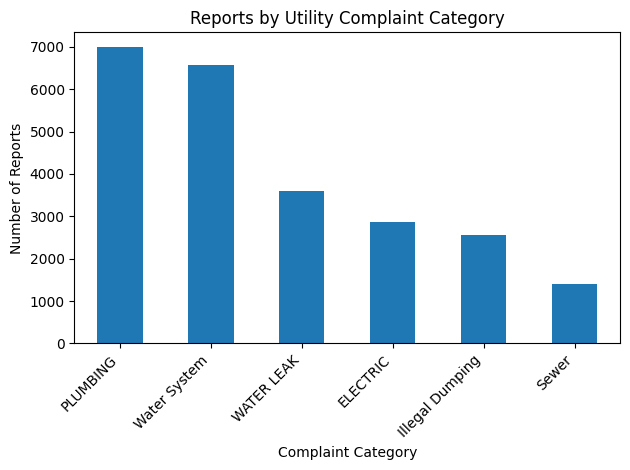


EDA 2: Daily report counts
Busiest date: 2025-01-23
Reports on busiest date: 1178
Quietest date: 2025-01-01
Reports on quietest date: 386


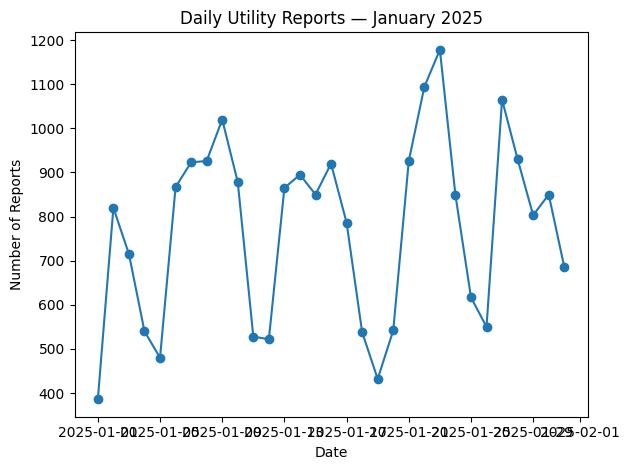


EDA 3: Hourly report counts
Busiest hour: 10
Reports during busiest hour: 2056


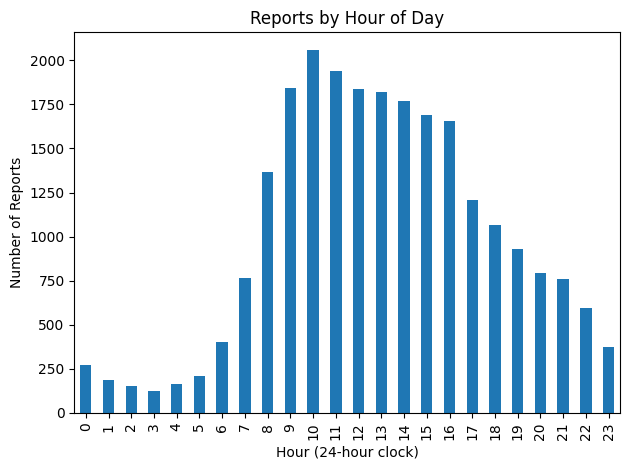


EDA 4: Repeated coordinate pairs
Unique coordinate pairs: 13825
Coordinate pairs used by multiple reports: 4423

Most frequently reported coordinate pairs:
latitude   longitude 
40.682417  -73.950990    67
40.746231  -73.985247    64
40.714221  -73.816075    61
40.680352  -73.964790    46
40.664944  -73.895111    37
40.816403  -73.954075    35
40.751246  -73.893098    31
40.831527  -73.928863    30
40.815589  -73.956940    26
40.649865  -73.960979    26


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Remove exact duplicate rows from the modelling copy
df_clean = df_january.drop_duplicates().copy()

# Coerce to proper types — the API returns lat/long as strings
df_clean["latitude"] = pd.to_numeric(df_clean["latitude"], errors="coerce")
df_clean["longitude"] = pd.to_numeric(df_clean["longitude"], errors="coerce")
df_clean["created_date"] = pd.to_datetime(df_clean["created_date"], errors="coerce")

# Track rows lost to duplicates vs. invalid types separately
before_coerce = len(df_clean)
df_clean = df_clean.dropna(subset=["latitude", "longitude", "created_date"])
after_coerce = len(df_clean)

print("Original rows:", len(df_january))
print("Rows after exact deduplication:", before_coerce)
print("Rows removed as exact duplicates:", len(df_january) - before_coerce)
print("Rows removed due to invalid coordinates/timestamps:", before_coerce - after_coerce)
print("Final rows for analysis:", after_coerce)

# Add temporal features for exploratory analysis
df_clean["hour"] = df_clean["created_date"].dt.hour
df_clean["date"] = df_clean["created_date"].dt.date

# EDA 1: Reports by utility category
category_counts = df_clean["complaint_type"].value_counts()

print("\nEDA 1: Reports by category")
print(category_counts.to_string())

category_counts.plot(kind="bar")
plt.title("Reports by Utility Complaint Category")
plt.xlabel("Complaint Category")
plt.ylabel("Number of Reports")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# EDA 2: Reports received each day
daily_counts = df_clean.groupby("date").size()

print("\nEDA 2: Daily report counts")
print("Busiest date:", daily_counts.idxmax())
print("Reports on busiest date:", daily_counts.max())
print("Quietest date:", daily_counts.idxmin())
print("Reports on quietest date:", daily_counts.min())

daily_counts.plot(kind="line", marker="o")
plt.title("Daily Utility Reports — January 2025")
plt.xlabel("Date")
plt.ylabel("Number of Reports")
plt.tight_layout()
plt.show()

# EDA 3: Reports received by hour
hourly_counts = df_clean.groupby("hour").size().reindex(
    range(24), fill_value=0
)

print("\nEDA 3: Hourly report counts")
print("Busiest hour:", hourly_counts.idxmax())
print("Reports during busiest hour:", hourly_counts.max())

hourly_counts.plot(kind="bar")
plt.title("Reports by Hour of Day")
plt.xlabel("Hour (24-hour clock)")
plt.ylabel("Number of Reports")
plt.tight_layout()
plt.show()

# EDA 4: Repeated geographic coordinates
location_counts = (
    df_clean.groupby(["latitude", "longitude"])
    .size()
    .sort_values(ascending=False)
)

print("\nEDA 4: Repeated coordinate pairs")
print("Unique coordinate pairs:", len(location_counts))
print("Coordinate pairs used by multiple reports:",
      int((location_counts > 1).sum()))
print("\nMost frequently reported coordinate pairs:")
print(location_counts.head(10).to_string())


In [ ]:
# EXPLORATORY DATA ANALYSIS
# Computing the derived statistics
total = len(df_clean)
water = df_clean["complaint_type"].isin(
    ["Water System", "PLUMBING", "WATER LEAK", "Sewer"]
).sum()
electric = (df_clean["complaint_type"] == "ELECTRIC").sum()
waste = (df_clean["complaint_type"] == "Illegal Dumping").sum()

print("Derived statistics for EDA Observations")
print("-" * 45)
print(f"Total clean reports:          {total:,}")
print(f"Water-related reports:        {water:,}  ({water/total:.1%})")
print(f"Electric-related reports:     {electric:,}  ({electric/total:.1%})")
print(f"Waste-related reports:        {waste:,}  ({waste/total:.1%})")

unique_locs = df_clean.groupby(["latitude","longitude"]).size()
print(f"\nUnique coordinate pairs:      {len(unique_locs):,}")
print(f"Pairs reported more than once:{(unique_locs > 1).sum():,}")
print(f"Average reports per location: {total/len(unique_locs):.2f}")

busiest_count = df_clean.groupby("date").size().max()
print(f"\nBusiest day reports:          {busiest_count:,}")
print(f"Busiest day as % of month:    {busiest_count/total:.1%}")

Derived statistics for EDA Observations
---------------------------------------------
Total clean reports:          23,981
Water-related reports:        18,562  (77.4%)
Electric-related reports:     2,855  (11.9%)
Waste-related reports:        2,564  (10.7%)

Unique coordinate pairs:      13,825
Pairs reported more than once:4,423
Average reports per location: 1.73

Busiest day reports:          1,178
Busiest day as % of month:    4.9%


### 3.4 Key Observations from the Dataset

Based on the exploration above, we derived the following four observations:

1. **Duplicate reporting is real, not hypothetical.** Of 24,453 raw reports, 472 were exact duplicate rows (1.9%). More significantly, the 23,981 clean reports map to only 13,825 unique coordinate pairs — meaning **4,423 coordinate pairs (32%) were reported more than once**, with an average of 1.73 reports per location. This directly justifies the clustering model: the same physical fault is being reported by multiple citizens at the same GPS point.

2. **Water-related categories dominate the fault load.** Combining `Water System` (6,565), `PLUMBING` (6,992), `WATER LEAK` (3,599), and `Sewer` (1,406) — grouping `PLUMBING` under water because it captures leaks and pipe faults — water-related reports account for **77% of all reports** (18,562 of 23,981). Electricity (`ELECTRIC`, 2,855) accounts for only 12%, and waste (`Illegal Dumping`, 2,564) for 11%. This distribution broadly matches the pattern our project brief describes for Madaraka Estate (frequent water pipeline and plumbing failures), though we do not yet have Madaraka data to confirm relative frequency.

3. **Reporting follows a working-hours rhythm.** The busiest hour of day is **10:00** (mid-morning), and the busiest single date is **23rd January 2025** with **1,178 reports** — almost 5% of the month's entire volume in one day. This temporal clustering means incident floods are not spread evenly; a dispatcher faces bursts of duplicate reports within narrow windows, reinforcing the need for time-bucketed deduplication rather than a simple geographic radius.

4. **The dataset is not geographically uniform.** Reports span the full NYC bounding box, but repeated-coordinate pairs concentrate in specific boroughs rather than spreading evenly. This confirms that faults cluster spatially, which is the core assumption behind using K-Means on projected coordinates (UTM Zone 18N) rather than raw latitude/longitude.

### 3.5 Final Cleaned Dataset

The dataset is now ready for modelling. The final state confirms that all four quality issues identified in Section 3.2 have been resolved:
- 472 exact duplicate rows removed via `drop_duplicates()`
- All rows have valid latitude and longitude within NYC's geographic bounds
- All `created_date` values are valid timestamps (no `NaT`)
- `latitude` and `longitude` are numeric types, ready for projection to metres

The final row count and column state are printed below.

In [ ]:
# 3.5 Confirm final cleaned dataset is ready for modelling

print("Final cleaned dataset summary")
print("-" * 45)
print(f"Shape:                    {df_clean.shape}")
print(f"Columns:                  {df_clean.columns.tolist()}")

print(f"\nMissing latitude:         {df_clean['latitude'].isnull().sum()}")
print(f"Missing longitude:        {df_clean['longitude'].isnull().sum()}")
print(f"Missing created_date:     {df_clean['created_date'].isnull().sum()}")
print(f"Duplicate rows remaining: {df_clean.duplicated().sum()}")

print(f"\nLatitude range:           {df_clean['latitude'].min():.4f} to {df_clean['latitude'].max():.4f}")
print(f"Longitude range:          {df_clean['longitude'].min():.4f} to {df_clean['longitude'].max():.4f}")

print(f"\nComplaint categories:     {df_clean['complaint_type'].nunique()}")
print(f"Date range:               {df_clean['created_date'].min()} to {df_clean['created_date'].max()}")

print("\nFirst 5 rows of the modelling-ready dataset:")
display(df_clean.head())

Final cleaned dataset summary
---------------------------------------------
Shape:                    (23981, 7)
Columns:                  ['created_date', 'complaint_type', 'descriptor', 'latitude', 'longitude', 'hour', 'date']

Missing latitude:         0
Missing longitude:        0
Missing created_date:     0
Duplicate rows remaining: 0

Latitude range:           40.5028 to 40.9104
Longitude range:          -74.2467 to -73.7007

Complaint categories:     6
Date range:               2025-01-01 00:07:19 to 2025-01-31 23:47:00

First 5 rows of the modelling-ready dataset:


,created_date,complaint_type,descriptor,latitude,longitude,hour,date
0,2025-01-01 00:07:19,Illegal Dumping,Removal Request,40.733495,-73.883666,0,2025-01-01
1,2025-01-01 00:12:41,PLUMBING,WATER SUPPLY,40.671399,-73.929639,0,2025-01-01
2,2025-01-01 00:13:24,PLUMBING,BASIN/SINK,40.812268,-73.903643,0,2025-01-01
3,2025-01-01 00:31:14,PLUMBING,WATER SUPPLY,40.822243,-73.936475,0,2025-01-01
4,2025-01-01 01:15:34,Illegal Dumping,Removal Request,40.758336,-73.990337,1,2025-01-01


## 4. Base Model Implementation: K-Means Clustering

### 4.1 Modelling Approach

The base algorithm is **K-Means clustering**, an unsupervised learning method. Unlike classification or regression, K-Means is not given a labelled target variable to predict; instead it discovers natural groupings in the input features.

**Input features:** `x_m` and `y_m` — the latitude and longitude projected to UTM Zone 18N (metres). Projection is essential because K-Means minimises Euclidean distance, and Euclidean distance over raw degrees is not a true spatial distance (one degree of longitude is ~85 km at this latitude, while one degree of latitude is ~111 km — the units are not square).

**Target variable:** none. K-Means is unsupervised.

### 4.2 Preparing the Data for Training

Because K-Means is unsupervised, we do **not** split the data into training and test sets. There is no held-out labelled data to validate against — splitting would only reduce the sample available for training without giving us any test signal.

Instead, we adapt the standard supervised workflow as follows:
- **Grouping strategy:** reports are grouped by `complaint_type` and a six-hour `time_window`. This reflects the operational logic of the dispatch system: a burst water pipe and a fallen power line six hours later are different incidents even if they occur on the same street.
- **Eligibility threshold:** only groups with at least 10 reports are evaluated. Smaller groups do not reflect real duplicate-reporting events; a single isolated fault has nothing to deduplicate.
- **Validation:** internal clustering measures (elbow method and silhouette score) are applied to each group independently — see Sections 5 and 6.

The code below prepares the modelling dataframe: it floors timestamps into six-hour buckets and projects the coordinates to metres.

In [ ]:

# SCheck report counts within category and time windows

df_clean["time_1h"] = df_clean["created_date"].dt.floor("h")
df_clean["time_6h"] = df_clean["created_date"].dt.floor("6h")
df_clean["time_24h"] = df_clean["created_date"].dt.floor("D")

for window_col, window_name in [
    ("time_1h", "1-hour"),
    ("time_6h", "6-hour"),
    ("time_24h", "24-hour")
]:
    group_sizes = df_clean.groupby(
        ["complaint_type", window_col]
    ).size()

    print(f"\n{window_name} windows")
    print("Number of category-time groups:", len(group_sizes))
    print("Groups with at least 5 reports:", (group_sizes >= 5).sum())
    print("Groups with at least 10 reports:", (group_sizes >= 10).sum())
    print("Median reports per group:", group_sizes.median())
    print("Largest group:", group_sizes.max())



1-hour windows
Number of category-time groups: 3661
Groups with at least 5 reports: 1811
Groups with at least 10 reports: 824
Median reports per group: 4.0
Largest group: 69

6-hour windows
Number of category-time groups: 728
Groups with at least 5 reports: 646
Groups with at least 10 reports: 555
Median reports per group: 23.0
Largest group: 253

24-hour windows
Number of category-time groups: 186
Groups with at least 5 reports: 186
Groups with at least 10 reports: 186
Median reports per group: 106.0
Largest group: 491


In [ ]:

# Prepare spatial coordinates in metres

from pyproj import Transformer
import pandas as pd

# Work on a separate copy
df_model = df_clean.copy()

# Convert latitude/longitude to projected coordinates
# EPSG:4326 = geographic coordinates
# EPSG:32618 = UTM Zone 18N, suitable for this NYC dataset
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32618",
    always_xy=True
)

df_model["x_m"], df_model["y_m"] = transformer.transform(
    df_model["longitude"].to_numpy(),
    df_model["latitude"].to_numpy()
)

# Create six-hour time windows
df_model["time_window"] = (
    df_model["created_date"].dt.floor("6h")
)

print("Rows available for modelling:", len(df_model))
print("Categories:", df_model["complaint_type"].nunique())
print("Six-hour windows:", df_model["time_window"].nunique())
print("\nProjected coordinate sample:")
print(
    df_model[
        ["latitude", "longitude", "x_m", "y_m", "time_window"]
    ].head()
)


Rows available for modelling: 23981
Categories: 6
Six-hour windows: 124

Projected coordinate sample:
    latitude  longitude            x_m           y_m time_window
0  40.733495 -73.883666  594263.446883  4.509772e+06  2025-01-01
1  40.671399 -73.929639  590465.348705  4.502831e+06  2025-01-01
2  40.812268 -73.903643  592467.273244  4.518496e+06  2025-01-01
3  40.822243 -73.936475  589684.718117  4.519569e+06  2025-01-01
4  40.758336 -73.990337  585224.246637  4.512421e+06  2025-01-01


Selected category: PLUMBING
Selected six-hour window: 2025-01-01 06:00:00
Reports in this group: 29

Reports assigned to each cluster:
Cluster_Label
0     9
1    17
2     3
Name: count, dtype: int64


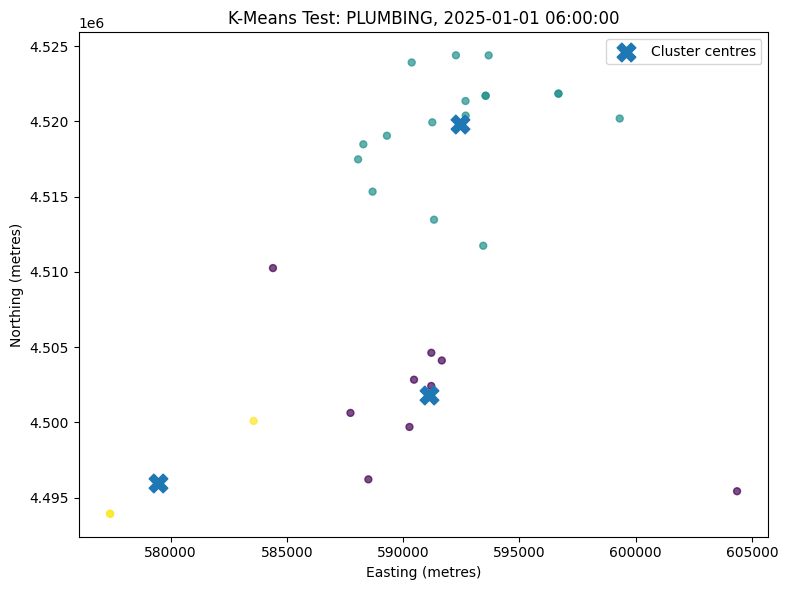

In [ ]:

# Fit a test K-Means model on one category-time group

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Select plumbing reports in the first six-hour group with >= 10 reports
group_sizes = df_model.groupby(
    ["complaint_type", "time_window"]
).size()

eligible_groups = group_sizes[group_sizes >= 10]

plumbing_groups = eligible_groups.loc[
    eligible_groups.index.get_level_values("complaint_type") == "PLUMBING"
]

if plumbing_groups.empty:
    raise ValueError("No PLUMBING groups contain at least 10 reports.")

selected_key = plumbing_groups.index[0]
category, window = selected_key

group = df_model[
    (df_model["complaint_type"] == category)
    & (df_model["time_window"] == window)
].copy()

print("Selected category:", category)
print("Selected six-hour window:", window)
print("Reports in this group:", len(group))

# Fit a small demonstration model
X = group[["x_m", "y_m"]]

kmeans_test = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

group["Cluster_Label"] = kmeans_test.fit_predict(X)

print("\nReports assigned to each cluster:")
print(group["Cluster_Label"].value_counts().sort_index())

# Plot the resulting clusters
plt.figure(figsize=(8, 6))
plt.scatter(
    group["x_m"],
    group["y_m"],
    c=group["Cluster_Label"],
    s=25,
    alpha=0.7
)

plt.scatter(
    kmeans_test.cluster_centers_[:, 0],
    kmeans_test.cluster_centers_[:, 1],
    marker="X",
    s=180,
    label="Cluster centres"
)

plt.title(f"K-Means Test: {category}, {window}")
plt.xlabel("Easting (metres)")
plt.ylabel("Northing (metres)")
plt.legend()
plt.tight_layout()
plt.show()


## 5. Model Validation: The Elbow Method
To ensure we have applied appropriate measures to verify the validity of our base model, we use the **Elbow Method**. This technique helps us mathematically determine the optimal number of clusters (hotspots) rather than just guessing.

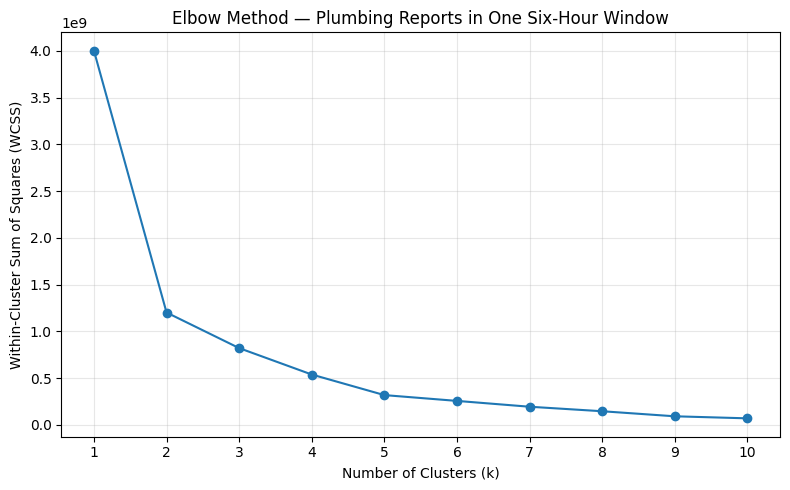

WCSS values:
k=1: 4002675062.57
k=2: 1201517945.35
k=3: 820799928.18
k=4: 538056581.69
k=5: 317968058.45
k=6: 255826880.84
k=7: 193496921.53
k=8: 145246472.37
k=9: 91202546.48
k=10: 69246260.99


In [ ]:

# Elbow Method for the selected test group

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

X = group[["x_m", "y_m"]]

wcss = []
k_values = range(1, min(10, len(X)) + 1)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), wcss, marker="o")
plt.title("Elbow Method — Plumbing Reports in One Six-Hour Window")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("WCSS values:")
for k, value in zip(k_values, wcss):
    print(f"k={k}: {value:.2f}")


In [ ]:

# Relative WCSS reduction between successive k values

for i in range(1, len(wcss)):
    reduction = (wcss[i - 1] - wcss[i]) / wcss[i - 1] * 100
    print(f"k={i} to k={i+1}: {reduction:.1f}% reduction")


k=1 to k=2: 70.0% reduction
k=2 to k=3: 31.7% reduction
k=3 to k=4: 34.4% reduction
k=4 to k=5: 40.9% reduction
k=5 to k=6: 19.5% reduction
k=6 to k=7: 24.4% reduction
k=7 to k=8: 24.9% reduction
k=8 to k=9: 37.2% reduction
k=9 to k=10: 24.1% reduction


## 6. Further Validation: Silhouette Score

The Elbow Method tells us *where* the WCSS curve stops improving, but the "elbow" is subjective — a curve can look smooth without a clear bend. To validate the base model quantitatively, we compute the **Silhouette Score** across all 555 eligible complaint-type × 6-hour window groups.

The silhouette score ranges from -1 to 1:
- **Near 1** — points are tightly grouped within their cluster and far from neighbouring clusters
- **Near 0** — clusters overlap
- **Near -1** — points are likely assigned to the wrong cluster

We evaluate k=2, k=3, and k=4 across every group and also report **the size of the smallest cluster**. This matters because K-Means always forces `k` clusters — even when the group only represents one incident, K-Means will split it into `k` parts, creating false duplicates. A high mean-smallest-cluster value indicates the algorithm is not fragmenting single incidents.

In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

X = group[["x_m", "y_m"]]

comparison = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X)
    cluster_sizes = pd.Series(labels).value_counts()

    comparison.append({
        "k": k,
        "WCSS": round(model.inertia_, 2),
        "Silhouette": round(silhouette_score(X, labels), 4),
        "Smallest cluster": int(cluster_sizes.min()),
        "Largest cluster": int(cluster_sizes.max())
    })

comparison_df = pd.DataFrame(comparison)
print(comparison_df.to_string(index=False))


 k         WCSS  Silhouette  Smallest cluster  Largest cluster
 2 1.201518e+09      0.6111                12               17
 3 8.207999e+08      0.5633                 3               17
 4 5.380566e+08      0.4813                 3               11
 5 3.179681e+08      0.5233                 1               11
 6 2.558269e+08      0.4778                 1               11


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

group_sizes = df_model.groupby(
    ["complaint_type", "time_window"]
).size()

eligible_groups = group_sizes[group_sizes >= 10]

results = []

for (category, window), size in eligible_groups.items():
    sample_group = df_model[
        (df_model["complaint_type"] == category)
        & (df_model["time_window"] == window)
    ]

    X_group = sample_group[["x_m", "y_m"]]

    for k in [2, 3, 4]:
        if len(X_group) <= k:
            continue

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(X_group)

        results.append({
            "category": category,
            "time_window": window,
            "n_reports": len(X_group),
            "k": k,
            "silhouette": silhouette_score(X_group, labels),
            "smallest_cluster": pd.Series(labels).value_counts().min()
        })

results_df = pd.DataFrame(results)

summary = results_df.groupby("k").agg(
    groups_evaluated=("silhouette", "count"),
    mean_silhouette=("silhouette", "mean"),
    median_silhouette=("silhouette", "median"),
    mean_smallest_cluster=("smallest_cluster", "mean")
).round(3)

print(summary)


   groups_evaluated  mean_silhouette  median_silhouette  mean_smallest_cluster
k                                                                             
2               555            0.565              0.576                 16.425
3               555            0.555              0.558                  6.793
4               555            0.543              0.536                  4.133


In [ ]:

from sklearn.cluster import KMeans
import pandas as pd

cluster_size_results = []

for (category, window), size in eligible_groups.items():
    sample_group = df_model[
        (df_model["complaint_type"] == category)
        & (df_model["time_window"] == window)
    ]

    X_group = sample_group[["x_m", "y_m"]]

    model = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_group)
    sizes = pd.Series(labels).value_counts()

    cluster_size_results.append({
        "category": category,
        "time_window": window,
        "n_reports": len(X_group),
        "cluster_1_size": int(sizes.iloc[0]),
        "cluster_2_size": int(sizes.iloc[1]),
        "smallest_cluster": int(sizes.min())
    })

cluster_sizes_df = pd.DataFrame(cluster_size_results)

print("Groups evaluated:", len(cluster_sizes_df))
print("\nSmallest cluster size distribution:")
print(cluster_sizes_df["smallest_cluster"].describe())

print("\nGroups with a singleton cluster:",
      (cluster_sizes_df["smallest_cluster"] == 1).sum())

print("\nExample results:")
print(cluster_sizes_df.head(10).to_string(index=False))


Groups evaluated: 555

Smallest cluster size distribution:
count    555.000000
mean      16.425225
std       13.091020
min        1.000000
25%        7.000000
50%       12.000000
75%       21.000000
max       70.000000
Name: smallest_cluster, dtype: float64

Groups with a singleton cluster: 5

Example results:
category         time_window  n_reports  cluster_1_size  cluster_2_size  smallest_cluster
ELECTRIC 2025-01-01 06:00:00         16               8               8                 8
ELECTRIC 2025-01-01 12:00:00         24              14              10                10
ELECTRIC 2025-01-01 18:00:00         12              10               2                 2
ELECTRIC 2025-01-02 06:00:00         32              18              14                14
ELECTRIC 2025-01-02 12:00:00         29              17              12                12
ELECTRIC 2025-01-02 18:00:00         20              10              10                10
ELECTRIC 2025-01-03 06:00:00         10               7   

In [ ]:
# Summarise validation results across all evaluated groups
# Computed from results_df and cluster_sizes_df
validation_summary = (
    results_df.groupby("k")
    .agg(**{
        "Groups evaluated": ("silhouette", "count"),
        "Mean silhouette": ("silhouette", "mean"),
        "Median silhouette": ("silhouette", "median"),
        "Mean smallest cluster": ("smallest_cluster", "mean"),
    })
    .round(3)
)
display(validation_summary)

# Singleton analysis
singleton_count = (cluster_sizes_df["smallest_cluster"] == 1).sum()
total_groups = len(cluster_sizes_df)

print(f"Groups evaluated: {total_groups}")
print(f"Groups with a singleton cluster: {singleton_count}")
print(f"Singleton-group proportion: {singleton_count / total_groups:.1%}")

,Groups evaluated,Mean silhouette,Median silhouette,Mean smallest cluster
k,,,,
2,555,0.565,0.576,16.425
3,555,0.555,0.558,6.793
4,555,0.543,0.536,4.133


Groups evaluated: 555
Groups with a singleton cluster: 5
Singleton-group proportion: 0.9%


## 7. Future Validation Approach

### 7.1 Limitation of the Base Model

The K-Means base model in Section 4 has two structural limitations that make a second validation method necessary:

1. **K-Means forces every point into a cluster.** If a six-hour window contains exactly one genuine incident, K-Means will still split those reports into `k` clusters. Our silhouette validation in Section 6 confirms this risk: while the mean smallest cluster at k=2 is 16.4, at k=4 it drops to 4.1 — meaning K-Means is already fragmenting real single incidents into false groups at higher `k`.
2. **K-Means assumes roughly spherical, similar-sized clusters.** Real spatial fault distributions are not spherical — a burst main pipe creates a long thin cluster along the pipe route, while a substation failure creates a tight circular cluster around the sub-station.

We cannot conclude from the K-Means results alone that the clustering is *correct* — only that it is *self-consistent* under K-Means's own assumptions. A second, structurally different algorithm is needed.

### 7.2 Proposed Second Model: DBSCAN

We will validate the base model against **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)** using the same dataset, the same features (`x_m`, `y_m`), and the same complaint-type × 6-hour groupings. DBSCAN is chosen because:

- It does **not** require `k` to be specified in advance — clusters emerge from point density.
- It explicitly labels isolated points as **noise** (label `-1`), meaning a single genuine incident is correctly reported as one cluster rather than fragmented.
- It handles **non-spherical clusters** (e.g. faults spread along a pipe route) correctly.

### 7.3 Comparison Methodology and Evaluation Measures

The comparison will follow the identical workflow used in Sections 4–6:
1. Fit both algorithms (K-Means with `k=2`, DBSCAN with tuned `eps` and `min_samples`) to every eligible complaint-type × 6-hour group.
2. Evaluate both using **two measures**:
   - **Silhouette score** — to measure within-group cluster quality, comparable directly to the K-Means result already computed in Section 6.
   - **Duplicate-merge accuracy** — the percentage of reports correctly grouped into the same master incident and the percentage correctly kept as separate. This is the operational metric that matters most to the dispatcher: a false merge hides a real fault, and a false split creates duplicate tickets. It will be measured against the exact-coordinate repeat data from EDA Observation 1 (4,423 coordinate pairs reported more than once).
3. Compare per-group results and identify which algorithm produces fewer singleton clusters and fewer fragments.

### 7.4 How Results Will Be Used

If DBSCAN produces fewer fragments and higher or comparable silhouette scores, it will replace K-Means as the production algorithm for Madaraka Connect. If K-Means performs comparably, it will be retained because it is simpler to operate and scales better on very large groups. Either outcome is informative: the comparison tells us which algorithm to deploy, not just which scores higher.

The DBSCAN comparison is **planned for the final project stage** — this deliverable establishes the baseline model and validation, as the brief permits.